In [1]:
import sqlite3
import pandas as pd

# 1. Carregar as duas bases tratadas da pasta data/processed/
df_vendas = pd.read_csv('../data/processed/online_retail_cleaned.csv', dtype={'InvoiceNo': str, 'StockCode': str})
df_rfm = pd.read_csv('../data/processed/rfm_clientes_segmentados.csv')

# 2. Criar conexão com o banco de dados SQLite (o arquivo será criado automaticamente)
caminho_banco = '../retail_intelligence.db'
conn = sqlite3.connect(caminho_banco)

# 3. Salvar os DataFrames como tabelas relacionais dentro do banco SQLite
df_vendas.to_sql('tb_vendas', conn, if_exists='replace', index=False)
df_rfm.to_sql('tb_clientes_rfm', conn, if_exists='replace', index=False)

print("Banco de dados 'retail_intelligence.db' criado com sucesso!")
print("Tabelas 'tb_vendas' e 'tb_clientes_rfm' carregadas no SQLite.")

Banco de dados 'retail_intelligence.db' criado com sucesso!
Tabelas 'tb_vendas' e 'tb_clientes_rfm' carregadas no SQLite.


In [2]:
# 1. Escrever a consulta SQL unindo vendas e clientes por segmento RFM
query_sql = """
SELECT 
    c.Segment AS Segmento_RFM,
    COUNT(DISTINCT c.CustomerID) AS Total_Clientes,
    COUNT(v.InvoiceNo) AS Total_Transacoes,
    ROUND(SUM(v.TotalSales), 2) AS Receita_Total_GBP,
    ROUND(AVG(v.TotalSales), 2) AS Ticket_Medio_Transacao_GBP
FROM tb_vendas v
INNER JOIN tb_clientes_rfm c ON v.CustomerID = c.CustomerID
GROUP BY c.Segment
ORDER BY Receita_Total_GBP DESC;
"""

# 2. Executar a query SQL via Pandas e carregar o resultado direto em um DataFrame
df_resultado_sql = pd.read_sql_query(query_sql, conn)

# 3. Exibir o resultado da consulta SQL
print("=== DESEMPENHO FINANCEIRO POR SEGMENTO RFM (SQL QUERY) ===")
df_resultado_sql

=== DESEMPENHO FINANCEIRO POR SEGMENTO RFM (SQL QUERY) ===


,Segmento_RFM,Total_Clientes,Total_Transacoes,Receita_Total_GBP,Ticket_Medio_Transacao_GBP
0,Champions,1139,250112,5927723.91,23.70
1,Loyal Customers,821,65908,1355744.71,20.57
2,At Risk,442,28975,557666.21,19.25
3,Hibernating / Lost,1065,23139,519408.57,22.45
4,Need Attention,201,9129,242865.34,26.60
5,Potential Loyalists,351,10370,161832.59,15.61
6,Promising / New,319,10251,146166.57,14.26


In [3]:
# 1. Query SQL para agrupar faturamento e pedidos por Ano-Mês
query_mensal_sql = """
SELECT 
    strftime('%Y-%m', InvoiceDate) AS Ano_Mes,
    COUNT(DISTINCT InvoiceNo) AS Total_Pedidos,
    COUNT(DISTINCT CustomerID) AS Clientes_Ativos,
    ROUND(SUM(TotalSales), 2) AS Faturamento_Mensal_GBP
FROM tb_vendas
GROUP BY Ano_Mes
ORDER BY Ano_Mes ASC;
"""

# 2. Executar a consulta no SQLite
df_faturamento_mensal = pd.read_sql_query(query_mensal_sql, conn)

# 3. Exibir a tabela formatada
print("=== EVOLUÇÃO MENSAL DO FATURAMENTO (TIME SERIES) ===")
df_faturamento_mensal

=== EVOLUÇÃO MENSAL DO FATURAMENTO (TIME SERIES) ===


,Ano_Mes,Total_Pedidos,Clientes_Ativos,Faturamento_Mensal_GBP
0,2010-12,1559,885,823746.14
1,2011-01,1086,741,691364.56
2,2011-02,1100,758,523631.89
3,2011-03,1454,974,717639.36
4,2011-04,1246,856,537808.62
5,2011-05,1681,1056,770536.02
6,2011-06,1533,991,761739.90
7,2011-07,1475,949,719221.19
8,2011-08,1361,935,759138.38
9,2011-09,1837,1266,1058590.17


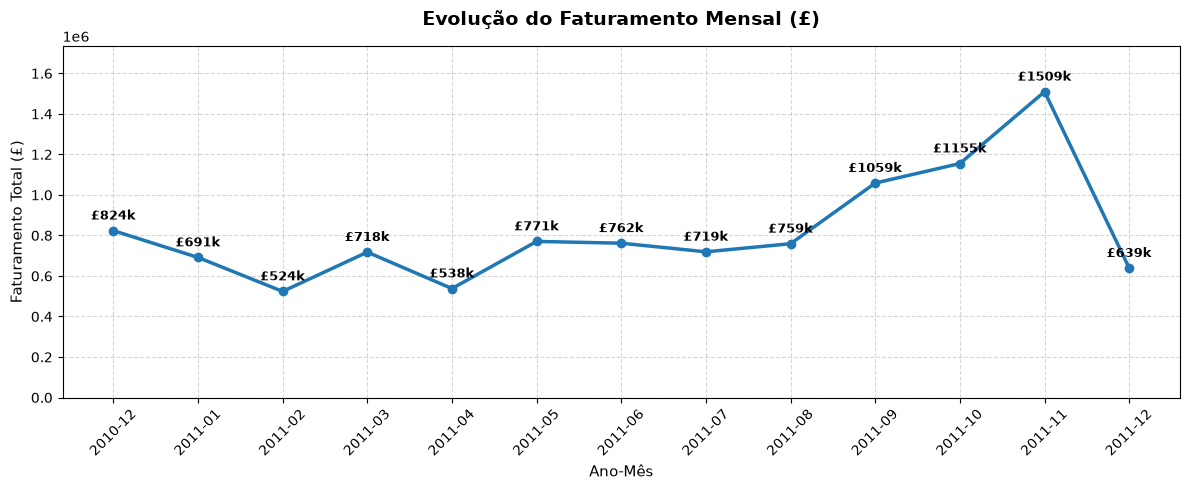

In [4]:
import matplotlib.pyplot as plt

# 1. Configurar a figura do gráfico
plt.figure(figsize=(12, 5))

# 2. Plotar a linha de faturamento mensal
plt.plot(
    df_faturamento_mensal['Ano_Mes'], 
    df_faturamento_mensal['Faturamento_Mensal_GBP'], 
    marker='o', 
    color='#1f77b4', 
    linewidth=2.5, 
    markersize=6
)

# 3. Adicionar rótulos com os valores acima de cada ponto
for i, txt in enumerate(df_faturamento_mensal['Faturamento_Mensal_GBP']):
    plt.annotate(
        f"£{txt/1e3:.0f}k", 
        (df_faturamento_mensal['Ano_Mes'][i], df_faturamento_mensal['Faturamento_Mensal_GBP'][i]),
        textcoords="offset points", 
        xytext=(0, 8), 
        ha='center', 
        fontsize=9, 
        fontweight='bold'
    )

# 4. Títulos e formatação visual
plt.title('Evolução do Faturamento Mensal (£)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Ano-Mês', fontsize=11)
plt.ylabel('Faturamento Total (£)', fontsize=11)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)

# Aumentar o limite do eixo Y para caber os rótulos de texto sem cortar
plt.ylim(0, df_faturamento_mensal['Faturamento_Mensal_GBP'].max() * 1.15)

plt.tight_layout()
plt.show()

In [5]:
# Encerrar a conexão com o banco de dados SQLite
conn.close()
print("Conexão com o banco de dados 'retail_intelligence.db' encerrada com sucesso!")

Conexão com o banco de dados 'retail_intelligence.db' encerrada com sucesso!
